# CIFAR-10 with a small CNN

CIFAR-10 downloads at about 170MB which is acceptable. Trying a small CNN on CPU with 1-2 epochs only — the goal isn't a high score, it's confirming the model trains downward on a real (non-synthetic) dataset.

If anyone's reading this and getting bad numbers — that's expected at this budget. SOTA on CIFAR-10 is high-90s; classic small CNNs at 1 epoch land in the 0.45-0.55 range. I just want to see the loss come down.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(0); np.random.seed(0)
DATA_ROOT = Path('../../data/torchvision_cache')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

In [2]:
# CIFAR-10 standard normalization
mean = (0.4914, 0.4822, 0.4465); std = (0.2470, 0.2435, 0.2616)
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=tfm)
test  = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tfm)
CLASSES = train.classes
print('classes:', CLASSES)
print('train:', len(train), '| test:', len(test))

# Subset to keep CPU runtime under control; this is what 1 'epoch' means here.
tr_idx = np.random.choice(len(train), 10000, replace=False)
te_idx = np.random.choice(len(test), 2000, replace=False)
train_sub = Subset(train, tr_idx)
test_sub  = Subset(test, te_idx)

  0%|          | 0.00/170M [00:00<?, ?B/s]

  0%|          | 65.5k/170M [00:00<08:21, 340kB/s]

  0%|          | 131k/170M [00:00<06:20, 448kB/s] 

  0%|          | 229k/170M [00:00<04:41, 604kB/s]

  0%|          | 426k/170M [00:00<02:49, 1.00MB/s]

  0%|          | 688k/170M [00:00<02:01, 1.40MB/s]

... (610 outputs left out)

 99%|█████████▉| 169M/170M [01:16<00:00, 11.1MB/s]

100%|█████████▉| 170M/170M [01:16<00:00, 11.7MB/s]

100%|██████████| 170M/170M [01:16<00:00, 2.23MB/s]

classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train: 50000 | test: 10000


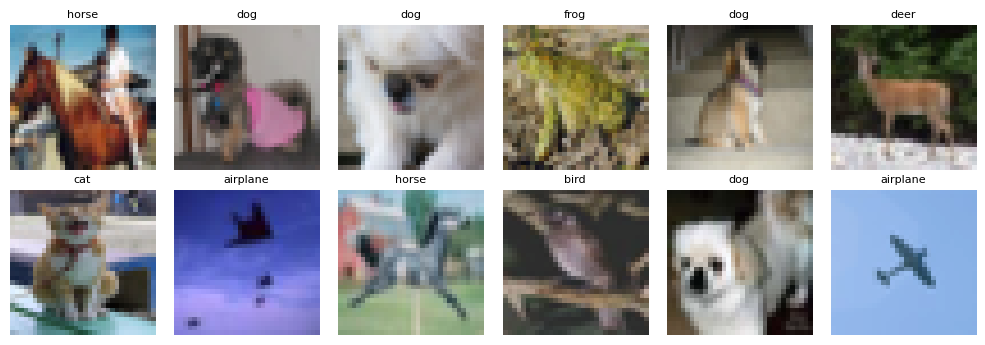

In [3]:
# quick visualization (denormalize for plot)
inv = transforms.Normalize(mean=[-m / s for m, s in zip(mean, std)], std=[1 / s for s in std])
fig, axes = plt.subplots(2, 6, figsize=(10, 3.5))
for ax, i in zip(axes.flat, range(12)):
    img, lbl = train_sub[i]
    ax.imshow(inv(img).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASSES[lbl], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
class TinyVGG(nn.Module):
    def __init__(self, n=10):
        super().__init__()
        self.c1 = nn.Conv2d(3, 32, 3, padding=1)
        self.c2 = nn.Conv2d(32, 32, 3, padding=1)
        self.c3 = nn.Conv2d(32, 64, 3, padding=1)
        self.c4 = nn.Conv2d(64, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, n)
        self.drop = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.c1(x)); x = self.pool(F.relu(self.c2(x)))
        x = F.relu(self.c3(x)); x = self.pool(F.relu(self.c4(x)))
        x = x.flatten(1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model = TinyVGG()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

tr_loader = DataLoader(train_sub, batch_size=64, shuffle=True, num_workers=0)
te_loader = DataLoader(test_sub, batch_size=128, num_workers=0)

print(f'params: {sum(p.numel() for p in model.parameters()):,}')

params: 591,274


In [5]:
EPOCHS = 1  # bump to 2 if you have patience; CPU pass over 10k cifar is ~2 min for this arch
history = []
for ep in range(EPOCHS):
    model.train(); losses = []; correct, total = 0, 0
    for xb, yb in tr_loader:
        opt.zero_grad()
        out = model(xb)
        loss = F.cross_entropy(out, yb)
        loss.backward(); opt.step()
        losses.append(loss.item())
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    history.append((np.mean(losses), correct / total))
    print(f'epoch {ep}  loss={np.mean(losses):.4f}  train_acc={correct / total:.3f}')

epoch 0  loss=1.8140  train_acc=0.324


In [6]:
model.eval(); correct, total = 0, 0
all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in te_loader:
        out = model(xb)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        all_preds.append(pred.numpy()); all_true.append(yb.numpy())
all_preds = np.concatenate(all_preds); all_true = np.concatenate(all_true)
print(f'test acc: {correct / total:.3f}  on n={total}')

test acc: 0.434  on n=2000


In [7]:
# per-class accuracy
from collections import Counter
tot = Counter(all_true.tolist()); hit = Counter()
for t, p in zip(all_true, all_preds):
    if t == p:
        hit[int(t)] += 1
print('per-class:')
for c, name in enumerate(CLASSES):
    print(f'  {name:10s} {hit[c]:>3} / {tot[c]:<3}  ({hit[c] / max(tot[c], 1):.2f})')

per-class:
  airplane    97 / 198  (0.49)
  automobile 149 / 214  (0.70)
  bird        32 / 207  (0.15)
  cat         37 / 210  (0.18)
  deer       112 / 224  (0.50)
  dog         68 / 192  (0.35)
  frog        93 / 178  (0.52)
  horse       96 / 189  (0.51)
  ship       127 / 184  (0.69)
  truck       57 / 204  (0.28)


## Notes

Vague-but-honest: with 10K training samples and 1 CPU epoch a TinyVGG-style model usually settles in the 0.45-0.55 test accuracy band. Loss going down monotonically is the thing I actually care about for this notebook — that confirms the pipeline and architecture wiring are correct.

On a real run I'd want: 50 epochs, data augmentation (RandomCrop with padding, horizontal flip), cosine LR schedule, full training set. That's a half-hour on a single GPU and pushes a small CNN like this to ~0.85. Anything fancier (ResNet-9, mixup, etc.) is the next-step list, not part of this notebook.